<a href="https://colab.research.google.com/github/ethereal-arko/Face_Mask_Detection_using_CNN/blob/main/Face_Mask_Detection_using_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Downloading and Extracting the Dataset

The Face Mask Detection dataset is downloaded from Kaggle using the Kaggle API.

The dataset contains two categories:
- With Mask
- Without Mask

After downloading, the ZIP file is extracted to access the image folders.

In [1]:
!pip install -q kaggle

from google.colab import userdata
import os

os.environ["KAGGLE_USERNAME"] = userdata.get("kaggle_username")
os.environ["KAGGLE_API_TOKEN"] = userdata.get("kaggle_api_token")

In [2]:
!kaggle datasets download -d omkargurav/face-mask-dataset

Dataset URL: https://www.kaggle.com/datasets/omkargurav/face-mask-dataset
License(s): unknown
100% 163M/163M [00:09<00:00, 17.8MB/s]



In [3]:
import zipfile

with zipfile.ZipFile('/content/face-mask-dataset.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/')

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [4]:
print("With Mask:", len(os.listdir('/content/data/with_mask')))
print("Without Mask:", len(os.listdir('/content/data/without_mask')))

With Mask: 3725
Without Mask: 3828


## 2. Importing Required Libraries

The following libraries are used for image processing, data manipulation, visualization, dataset splitting, and building the Convolutional Neural Network (CNN).

- NumPy: Numerical operations and array manipulation.
- Matplotlib: Image visualization and plotting.
- Seaborn: Statistical visualization.
- PIL: Loading, resizing, and converting images.
- OpenCV: Image processing and custom image prediction.
- Scikit-learn: Dataset splitting and model evaluation.
- TensorFlow/Keras: Building and training the CNN model.

In [5]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
import cv2

import tensorflow as tf
from tensorflow import keras

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

tf.keras.utils.set_random_seed(42)

## 3. Dataset Inspection

In this section, we inspect the image files available in both categories.

We will examine:
- Image filenames
- Number of images in each category
- Image dimensions
- Image file formats

This helps us understand the dataset before preprocessing.

In [8]:
withmask_files = os.listdir('/content/data/with_mask')
withoutmask_files = os.listdir('/content/data/without_mask')

print("First 5 With Mask Images:")
print(withmask_files[:5])

print("\nFirst 5 Without Mask Images:")
print(withoutmask_files[:5])


First 5 With Mask Images:
['with_mask_2860.jpg', 'with_mask_752.jpg', 'with_mask_2945.jpg', 'with_mask_312.jpg', 'with_mask_1281.jpg']

First 5 Without Mask Images:
['without_mask_2454.jpg', 'without_mask_37.jpg', 'without_mask_2224.jpg', 'without_mask_3718.jpg', 'without_mask_1167.jpg']


In [7]:
# Load one image from each category
withmask_image = Image.open(
    '/content/data/with_mask/' + withmask_files[0]
)

withoutmask_image = Image.open(
    '/content/data/without_mask/' + withoutmask_files[0]
)

print("With Mask Image Size:", withmask_image.size)
print("With Mask Image Mode:", withmask_image.mode)

print("\nWithout Mask Image Size:", withoutmask_image.size)
print("Without Mask Image Mode:", withoutmask_image.mode)

With Mask Image Size: (200, 200)
With Mask Image Mode: RGB

Without Mask Image Size: (225, 225)
Without Mask Image Mode: RGB


## 4. Visualizing Sample Images

In this section, we visualize sample images from both categories to understand the visual characteristics of the dataset.

This helps us observe differences between images with masks and without masks.

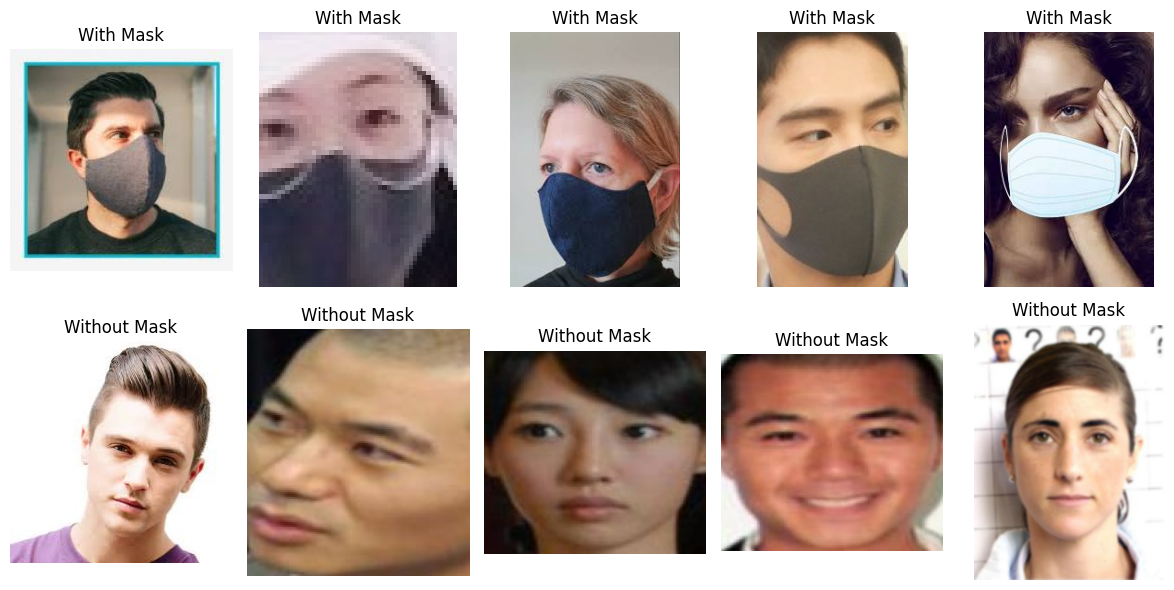

In [9]:
plt.figure(figsize=(12, 6))

# Display 5 images with masks
for i in range(5):
    plt.subplot(2, 5, i + 1)

    image = Image.open(
        '/content/data/with_mask/' + withmask_files[i]
    )

    plt.imshow(image)
    plt.title("With Mask")
    plt.axis('off')

# Display 5 images without masks
for i in range(5):
    plt.subplot(2, 5, i + 6)

    image = Image.open(
        '/content/data/without_mask/' + withoutmask_files[i]
    )

    plt.imshow(image)
    plt.title("Without Mask")
    plt.axis('off')

plt.tight_layout()
plt.show()

## 5. Class Distribution

In this section, we visualize the number of images available in each category.

Understanding the class distribution helps us determine whether the dataset is balanced or imbalanced.

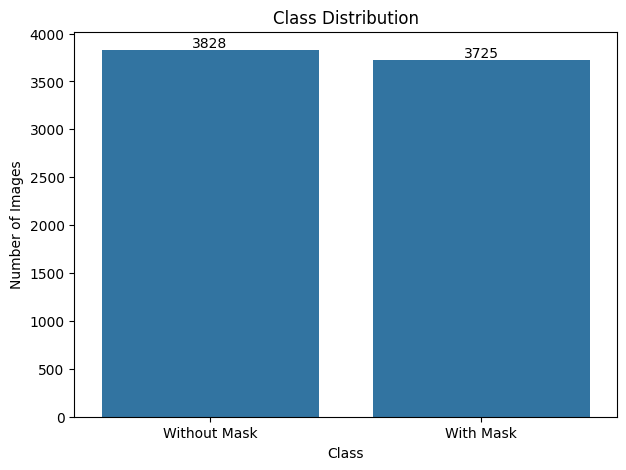

In [10]:
class_names = ['Without Mask', 'With Mask']
class_counts = [len(withoutmask_files), len(withmask_files)]

plt.figure(figsize=(7, 5))

sns.barplot(x=class_names, y=class_counts)

plt.title('Class Distribution')
plt.xlabel('Class')
plt.ylabel('Number of Images')

for i, count in enumerate(class_counts):
    plt.text(i, count + 30, str(count), ha='center')

plt.show()

## 6. Image Preprocessing

In this section, we load the images from both categories and preprocess them.

The preprocessing steps include:
- Loading each image.
- Converting images into RGB format.
- Resizing images to 128 × 128 pixels.
- Converting images into NumPy arrays.
- Assigning labels to each image.

Labels:
- 0: Without Mask
- 1: With Mask

In [11]:
IMG_SIZE = (128, 128)

data = []
labels = []

# Processing images with masks
for img_file in sorted(withmask_files):

    image_path = os.path.join('/content/data/with_mask', img_file)

    image = Image.open(image_path).convert('RGB')
    image = image.resize(IMG_SIZE)

    data.append(np.array(image))
    labels.append(1)


# Processing images without masks
for img_file in sorted(withoutmask_files):

    image_path = os.path.join('/content/data/without_mask', img_file)

    image = Image.open(image_path).convert('RGB')
    image = image.resize(IMG_SIZE)

    data.append(np.array(image))
    labels.append(0)

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


In [12]:
X = np.array(data, dtype=np.uint8)
y = np.array(labels, dtype=np.int32)

print("Image Data Shape:", X.shape)
print("Labels Shape:", y.shape)

print("\nImage Data Type:", X.dtype)
print("Labels Data Type:", y.dtype)

print("\nMinimum Pixel Value:", X.min())
print("Maximum Pixel Value:", X.max())

print("\nClass Distribution:")
print("Without Mask (0):", np.sum(y == 0))
print("With Mask (1):", np.sum(y == 1))

Image Data Shape: (7553, 128, 128, 3)
Labels Shape: (7553,)

Image Data Type: uint8
Labels Data Type: int32

Minimum Pixel Value: 0
Maximum Pixel Value: 255

Class Distribution:
Without Mask (0): 3828
With Mask (1): 3725


## 7. Splitting the Dataset

In this section, we divide the dataset into training, validation, and testing sets.

- Training set: Used to train the CNN model.
- Validation set: Used to monitor model performance during training.
- Testing set: Used for final model evaluation.

We use stratified splitting to maintain a similar class distribution across all three sets.

In [13]:
# First split: Training + Validation and Testing
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Second split: Training and Validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.1,
    random_state=42,
    stratify=y_train_full
)

print("Training Images:", X_train.shape)
print("Validation Images:", X_val.shape)
print("Testing Images:", X_test.shape)

Training Images: (5437, 128, 128, 3)
Validation Images: (605, 128, 128, 3)
Testing Images: (1511, 128, 128, 3)


In [14]:
print("Training Class Distribution:")
print("Without Mask:", np.sum(y_train == 0))
print("With Mask:", np.sum(y_train == 1))

print("\nValidation Class Distribution:")
print("Without Mask:", np.sum(y_val == 0))
print("With Mask:", np.sum(y_val == 1))

print("\nTesting Class Distribution:")
print("Without Mask:", np.sum(y_test == 0))
print("With Mask:", np.sum(y_test == 1))

Training Class Distribution:
Without Mask: 2755
With Mask: 2682

Validation Class Distribution:
Without Mask: 307
With Mask: 298

Testing Class Distribution:
Without Mask: 766
With Mask: 745


## 8. Image Normalization

Image pixel values originally range from 0 to 255.

To make model training more stable, we normalize the pixel values to the range of 0 to 1 by dividing each pixel value by 255.

In [15]:
X_train = X_train.astype('float32') / 255.0
X_val = X_val.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

print("Training Data Shape:", X_train.shape)
print("Validation Data Shape:", X_val.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Data Type:", X_train.dtype)

print("\nMinimum Pixel Value:", X_train.min())
print("Maximum Pixel Value:", X_train.max())

Training Data Shape: (5437, 128, 128, 3)
Validation Data Shape: (605, 128, 128, 3)
Testing Data Shape: (1511, 128, 128, 3)

Training Data Type: float32

Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0


## 9. Building the CNN Model

In this section, we build a Convolutional Neural Network (CNN) for face mask classification.

The model consists of:
- Convolutional layers for extracting image features.
- Max pooling layers for reducing spatial dimensions.
- Global Average Pooling for reducing the number of parameters.
- Dense layers for classification.
- Dropout for reducing overfitting.
- A Softmax output layer for predicting two classes.

In [16]:
num_of_classes = 2

model = keras.Sequential([
    keras.layers.Input(shape=(128, 128, 3)),

    keras.layers.Conv2D(32, (3, 3), activation='relu'),
    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.Conv2D(64, (3, 3), activation='relu'),
    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.GlobalAveragePooling2D(),

    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dropout(0.5),

    keras.layers.Dense(num_of_classes, activation='softmax')
])

In [17]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [18]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,970 (109.26 KB)

 Trainable params: 27,970 (109.26 KB)

 Non-trainable params: 0 (0.00 B)

## 10. Training the CNN Model

In this section, we train the CNN model using the training dataset.

The validation dataset is used to monitor the model's performance on unseen data during training.

We train the model for 10 epochs with a batch size of 32.

In [19]:
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=32
)

Epoch 1/10
170/170 ━━━━━━━━━━━━━━━━━━━━ 22s 81ms/step - accuracy: 0.6732 - loss: 0.6039 - val_accuracy: 0.7603 - val_loss: 0.5350
Epoch 2/10
170/170 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.7287 - loss: 0.5500 - val_accuracy: 0.7603 - val_loss: 0.5191
Epoch 3/10
170/170 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.7364 - loss: 0.5350 - val_accuracy: 0.7835 - val_loss: 0.5067
Epoch 4/10
170/170 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.7364 - loss: 0.5343 - val_accuracy: 0.7868 - val_loss: 0.5017
Epoch 5/10
170/170 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.7397 - loss: 0.5300 - val_accuracy: 0.7785 - val_loss: 0.4987
Epoch 6/10
170/170 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.7462 - loss: 0.5269 - val_accuracy: 0.7884 - val_loss: 0.4921
Epoch 7/10
170/170 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.7506 - loss: 0.5188 - val_accuracy: 0.7884 - val_loss: 0.4906
Epoch 8/10
170/170 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.7508 - loss: 0.5173 - val_acc

## 11. Visualizing Training Performance

In this section, we visualize the training and validation performance of the CNN model.

We plot:
- Training and validation loss.
- Training and validation accuracy.

These plots help us understand the model's learning behavior and identify possible overfitting or underfitting.

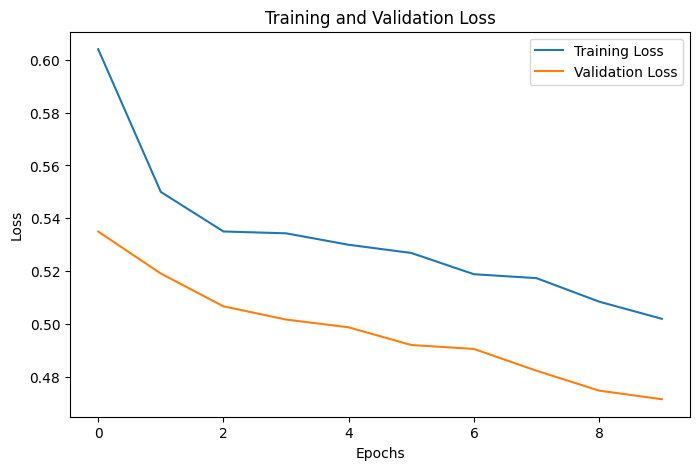

In [20]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

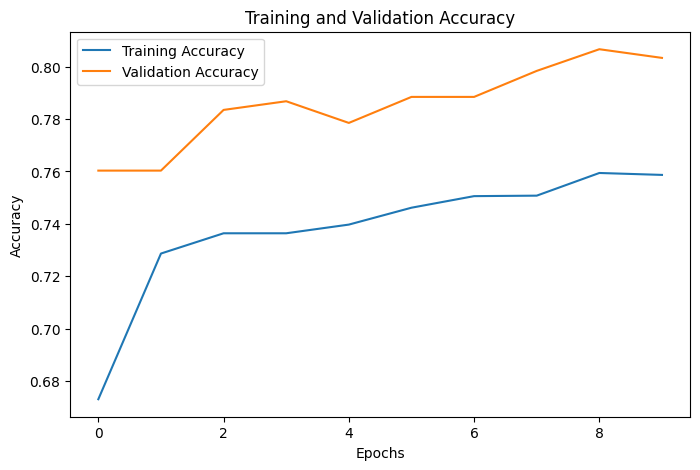

In [21]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

## 12. Model Evaluation

In this section, we evaluate the trained CNN model using the test dataset.

The test dataset contains images that were not used during model training or validation.

We evaluate the model using test loss and test accuracy.

In [22]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - accuracy: 0.7929 - loss: 0.4699
Test Loss: 0.4699070155620575
Test Accuracy: 0.7928524017333984


## 13. Confusion Matrix and Classification Report

In this section, we perform a detailed evaluation of the CNN model using:

- Confusion Matrix
- Precision
- Recall
- F1-score

These metrics help us understand how accurately the model identifies each category.

In [23]:
y_pred_prob = model.predict(X_test)

y_pred = np.argmax(y_pred_prob, axis=1)

print("Actual Labels:", y_test[:10])
print("Predicted Labels:", y_pred[:10])

48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step
Actual Labels: [0 0 0 0 1 0 1 0 0 0]
Predicted Labels: [1 1 0 0 1 0 1 1 0 0]


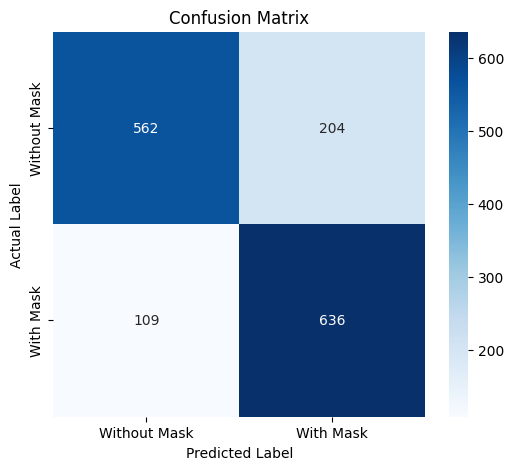

In [24]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Without Mask', 'With Mask'],
    yticklabels=['Without Mask', 'With Mask']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix')
plt.show()

In [25]:
print(classification_report(
    y_test,
    y_pred,
    target_names=['Without Mask', 'With Mask']
))

              precision    recall  f1-score   support

Without Mask       0.84      0.73      0.78       766
   With Mask       0.76      0.85      0.80       745

    accuracy                           0.79      1511
   macro avg       0.80      0.79      0.79      1511
weighted avg       0.80      0.79      0.79      1511



## 14. Improving Model Training

The baseline CNN model achieved 79.29% test accuracy after 10 epochs.

Since the validation loss was still decreasing at the end of training, we continue training to investigate whether additional epochs can improve the model's performance.

We use Early Stopping to prevent unnecessary training and ReduceLROnPlateau to adjust the learning rate when validation performance stops improving.

In [26]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

fine_tune_history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    callbacks=[early_stopping, reduce_lr]
)

Epoch 1/20
170/170 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.7554 - loss: 0.4979 - val_accuracy: 0.7950 - val_loss: 0.4688 - learning_rate: 0.0010
Epoch 2/20
170/170 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.7683 - loss: 0.4876 - val_accuracy: 0.7983 - val_loss: 0.4638 - learning_rate: 0.0010
Epoch 3/20
170/170 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.7666 - loss: 0.4825 - val_accuracy: 0.8000 - val_loss: 0.4569 - learning_rate: 0.0010
Epoch 4/20
170/170 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.7780 - loss: 0.4711 - val_accuracy: 0.8050 - val_loss: 0.4468 - learning_rate: 0.0010
Epoch 5/20
170/170 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.7791 - loss: 0.4708 - val_accuracy: 0.8050 - val_loss: 0.4475 - learning_rate: 0.0010
Epoch 6/20
170/170 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.7820 - loss: 0.4628 - val_accuracy: 0.8099 - val_loss: 0.4361 - learning_rate: 0.0010
Epoch 7/20
170/170 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.7918 - loss: 0.

In [27]:
improved_test_loss, improved_test_accuracy = model.evaluate(
    X_test,
    y_test
)

print("Improved Test Loss:", improved_test_loss)
print("Improved Test Accuracy:", improved_test_accuracy)

48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8802 - loss: 0.2996
Improved Test Loss: 0.29955431818962097
Improved Test Accuracy: 0.8802117705345154


In [28]:
baseline_accuracy = 0.7928524

print("Baseline Test Accuracy:",
      round(baseline_accuracy * 100, 2), "%")

print("Improved Test Accuracy:",
      round(improved_test_accuracy * 100, 2), "%")

improvement = (improved_test_accuracy - baseline_accuracy) * 100

print("Accuracy Improvement:",
      round(improvement, 2), "percentage points")

Baseline Test Accuracy: 79.29 %
Improved Test Accuracy: 88.02 %
Accuracy Improvement: 8.74 percentage points


In [29]:
improved_y_pred_prob = model.predict(X_test)

improved_y_pred = np.argmax(improved_y_pred_prob, axis=1)

48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step


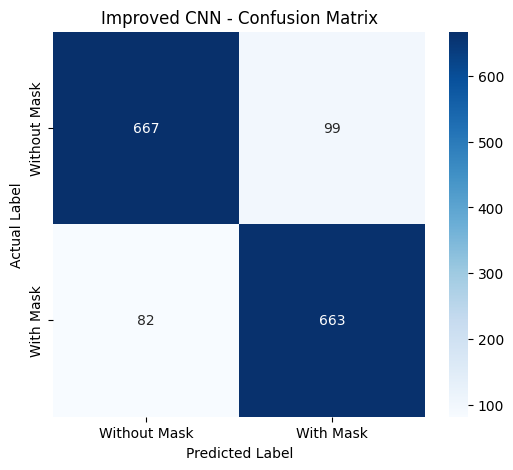

In [30]:
improved_cm = confusion_matrix(y_test, improved_y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    improved_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Without Mask', 'With Mask'],
    yticklabels=['Without Mask', 'With Mask']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Improved CNN - Confusion Matrix')
plt.show()

In [31]:
print(classification_report(
    y_test,
    improved_y_pred,
    target_names=['Without Mask', 'With Mask']
))

              precision    recall  f1-score   support

Without Mask       0.89      0.87      0.88       766
   With Mask       0.87      0.89      0.88       745

    accuracy                           0.88      1511
   macro avg       0.88      0.88      0.88      1511
weighted avg       0.88      0.88      0.88      1511



## 17. Baseline vs Improved Model Comparison

In this section, we compare the baseline CNN model with the improved CNN model.

The comparison is based on:
- Test Accuracy
- Test Loss
- Precision
- Recall
- F1-score

This comparison helps us understand the effectiveness of the improved training strategy.

In [32]:
import pandas as pd

comparison = pd.DataFrame({
    'Metric': [
        'Test Accuracy',
        'Test Loss',
        'Macro Precision',
        'Macro Recall',
        'Macro F1-score'
    ],
    'Baseline CNN': [
        79.29,
        0.4699,
        80,
        79,
        79
    ],
    'Improved CNN': [
        88.02,
        0.2996,
        88,
        88,
        88
    ]
})

comparison

,Metric,Baseline CNN,Improved CNN
0,Test Accuracy,79.2900,88.0200
1,Test Loss,0.4699,0.2996
2,Macro Precision,80.0000,88.0000
3,Macro Recall,79.0000,88.0000
4,Macro F1-score,79.0000,88.0000


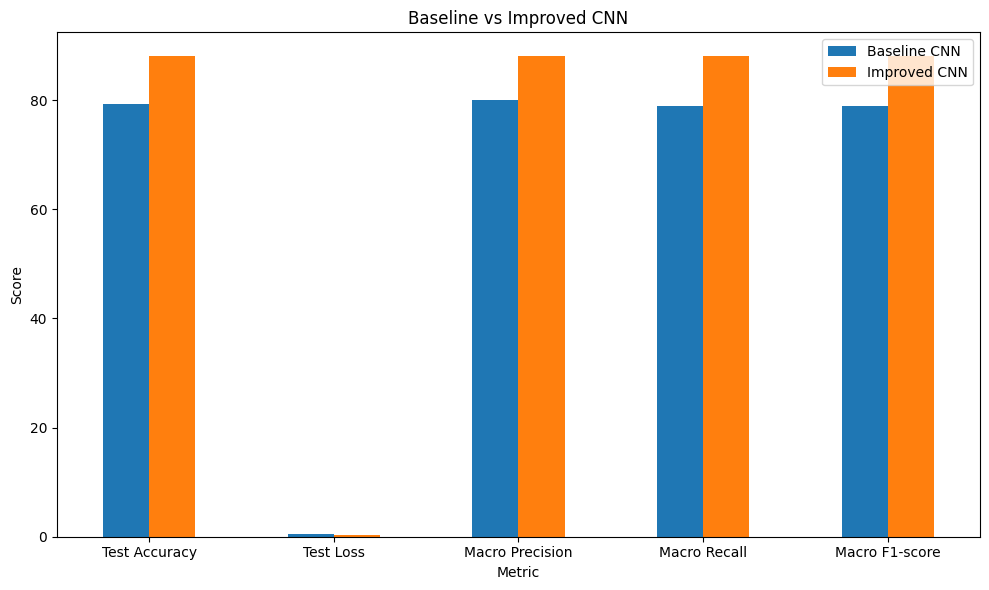

In [33]:
comparison.set_index('Metric').plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Baseline vs Improved CNN')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

## 18. Building a Predictive System

In this section, we build a simple predictive system that allows users to upload an image and classify it as either With Mask or Without Mask.

The uploaded image undergoes the same preprocessing steps used during model training.

In [35]:
from google.colab import files

uploaded = files.upload()

image_path = next(iter(uploaded))

Saving maskphoto.avif to maskphoto.avif


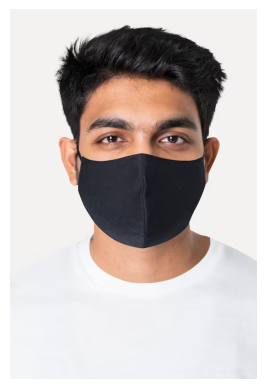

In [36]:
input_image = Image.open(image_path).convert('RGB')

input_image_resized = input_image.resize((128, 128))

plt.imshow(input_image)
plt.axis('off')
plt.show()

In [37]:
input_image_array = np.array(
    input_image_resized,
    dtype=np.float32
) / 255.0

input_image_reshaped = np.expand_dims(
    input_image_array,
    axis=0
)

prediction = model.predict(input_image_reshaped)

predicted_label = np.argmax(prediction, axis=1)[0]

class_names = {
    0: 'Without Mask',
    1: 'With Mask'
}

print("Prediction:", class_names[predicted_label])
print("Without Mask Probability:", round(float(prediction[0][0]) * 100, 2), "%")
print("With Mask Probability:", round(float(prediction[0][1]) * 100, 2), "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
Prediction: With Mask
Without Mask Probability: 0.37 %
With Mask Probability: 99.63 %
